<a href="https://colab.research.google.com/github/mmm10138/Machine-Learning/blob/main/Dynamic_Programming.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this notebook we implement dynamic programming on examples in discrete time and finite spaces.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# Example 1: 1D Grid World

## Model 1 without noise

### Definition of the problem

In [8]:
class GridWorld:
    """
    One-dimensional grid world with states x_min, ..., x_max.

    p_noise can be:
      - one distribution of shape (3,), used at every time; or
      - an array of shape (T, 3), with one distribution per time.
    """

    def __init__(
        self, x_min, x_max, target, T, p_noise,
        state_cost=2.0, action_cost=1.0, terminal_weight=0.0,
    ):
        self.states = np.arange(x_min, x_max + 1)
        self.actions = np.array([-1, 0, 1])
        self.noise = np.array([-1, 0, 1])

        self.x_min = x_min
        self.x_max = x_max
        self.target = target
        self.T = T

        self.state_cost = state_cost
        self.action_cost = action_cost
        self.terminal_weight = terminal_weight

        self.p_noise = np.asarray(p_noise, dtype=float)

    def cost(self, x, a):
        # Penalize being away from the target and taking a nonzero action.
        return (
            self.state_cost * np.abs(x - self.target) +
            self.action_cost * np.abs(a)
        )

    def terminal_cost(self, x):
        # Terminal cost is proportional to distance from the target.
        return self.terminal_weight * np.abs(x - self.target)

    def transition(self, x, a, e):
        # Apply action and noise, then clip the next state to the grid.
        return np.clip(x+a+e,self.x_min,self.x_max)


# 10-state grid world, without noise
env_grid = GridWorld(
    x_min=0,
    x_max=9,
    target=2,
    T=10,
    p_noise=np.tile([0.0,1.0,0.0],(10,1))
)

### DPP to compute the value function

In [9]:
# Dynamic programming algorithm (backward in time)

def compute_value_function(env):
    num_states = len(env.states)

    # Values at times 0, ..., T; actions at times 0, ..., T - 1.
    V = np.zeros((env.T + 1, num_states))
    alpha = np.zeros((env.T, num_states), dtype=int)

    # Terminal values
    for j, x in enumerate(env.states):
        V[env.T, j] = env.terminal_cost(x)

    # Backward induction
    for t in reversed(range(env.T)):
        for j, x in enumerate(env.states):
            expected_values = []

            for a in env.actions:
                expected_future_value = 0.0

                for p, e in zip(env.p_noise[t], env.noise):
                    next_x = env.transition(x, a, e)
                    next_index = next_x - env.x_min

                    expected_future_value += p*V[t+1,next_index]

                # Use dynamic programming formula
                expected_values.append(
                    env.cost(x, a) + expected_future_value
                )

            # For an exact tie, argmin returns the first minimizing action.
            # Floating-point rounding can make theoretical ties look unequal.
            best_action_index = int(np.argmin(expected_values))

            V[t, j] = expected_values[best_action_index]
            alpha[t, j] = env.actions[best_action_index]

    return V, alpha

In [10]:
V_grid, alpha_grid = compute_value_function(env_grid)

print("Optimal Value Function V:\n", V_grid)
print("Optimal Control Policy alpha:\n", alpha_grid)

Optimal Value Function V:
 [[ 8.  3.  0.  3.  8. 15. 24. 35. 48. 63.]
 [ 8.  3.  0.  3.  8. 15. 24. 35. 48. 63.]
 [ 8.  3.  0.  3.  8. 15. 24. 35. 48. 63.]
 [ 8.  3.  0.  3.  8. 15. 24. 35. 48. 62.]
 [ 8.  3.  0.  3.  8. 15. 24. 35. 47. 59.]
 [ 8.  3.  0.  3.  8. 15. 24. 34. 44. 54.]
 [ 8.  3.  0.  3.  8. 15. 23. 31. 39. 47.]
 [ 8.  3.  0.  3.  8. 14. 20. 26. 32. 38.]
 [ 7.  3.  0.  3.  7. 11. 15. 19. 23. 27.]
 [ 4.  2.  0.  2.  4.  6.  8. 10. 12. 14.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]]
Optimal Control Policy alpha:
 [[ 1  1  0 -1 -1 -1 -1 -1 -1 -1]
 [ 1  1  0 -1 -1 -1 -1 -1 -1 -1]
 [ 1  1  0 -1 -1 -1 -1 -1 -1 -1]
 [ 1  1  0 -1 -1 -1 -1 -1 -1 -1]
 [ 1  1  0 -1 -1 -1 -1 -1 -1 -1]
 [ 1  1  0 -1 -1 -1 -1 -1 -1 -1]
 [ 1  1  0 -1 -1 -1 -1 -1 -1 -1]
 [ 1  1  0 -1 -1 -1 -1 -1 -1 -1]
 [ 1  1  0 -1 -1 -1 -1 -1 -1 -1]
 [ 0  0  0  0  0  0  0  0  0  0]]


### Plotting the result

In [11]:
def plot_grid_comparison(env, results):
    """
    Plot value functions and policies for one or more scenarios.

    results is a list of (label, V, alpha) tuples.
    The scenarios must use the same states and horizon.
    """

    fig, axes = plt.subplots(
        2, len(results),
        figsize=(5 * len(results), 7),
        squeeze=False,
        constrained_layout=True,
    )

    # Use the same value scale for every scenario.
    values = [V for _, V, _ in results]
    vmin = min(V.min() for V in values)
    vmax = max(V.max() for V in values)

    if vmin == vmax:
        vmax = vmin + 1.0

    # Fixed colors for actions -1, 0, and 1.
    action_cmap = ListedColormap(["#D55E00", "#D9D9D9", "#0072B2"])
    action_norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], action_cmap.N)

    for col, (label, V, alpha) in enumerate(results):
        value_plot = axes[0, col].imshow(
            V,
            origin="lower",
            aspect="auto",
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            extent=[
                env.x_min - 0.5, env.x_max + 0.5,
                -0.5, env.T + 0.5,
            ],
            interpolation="nearest",
        )

        action_plot = axes[1, col].imshow(
            alpha,
            origin="lower",
            aspect="auto",
            cmap=action_cmap,
            norm=action_norm,
            extent=[
                env.x_min - 0.5, env.x_max + 0.5,
                -0.5, env.T - 0.5,
            ],
            interpolation="nearest",
        )

        axes[0, col].set_title(label)

        for row in range(2):
            axes[row, col].set_xlabel("State x")
            axes[row, col].set_ylabel("Time t")
            axes[row, col].set_xticks(env.states)

    fig.colorbar(value_plot, ax=axes[0, :], label="Value")
    fig.colorbar(
        action_plot, ax=axes[1, :],
        ticks=[-1, 0, 1], label="Action",
    )

    plt.show()

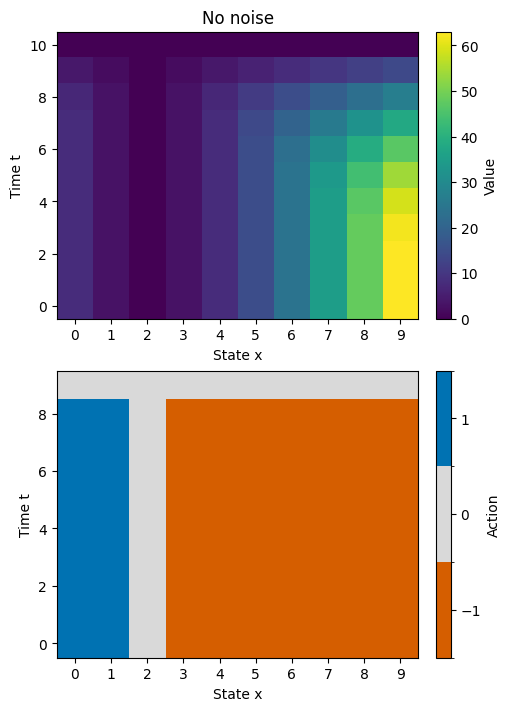

In [12]:
plot_grid_comparison(
    env_grid,
    [("No noise", V_grid, alpha_grid)],
)

## Model 1 with noise

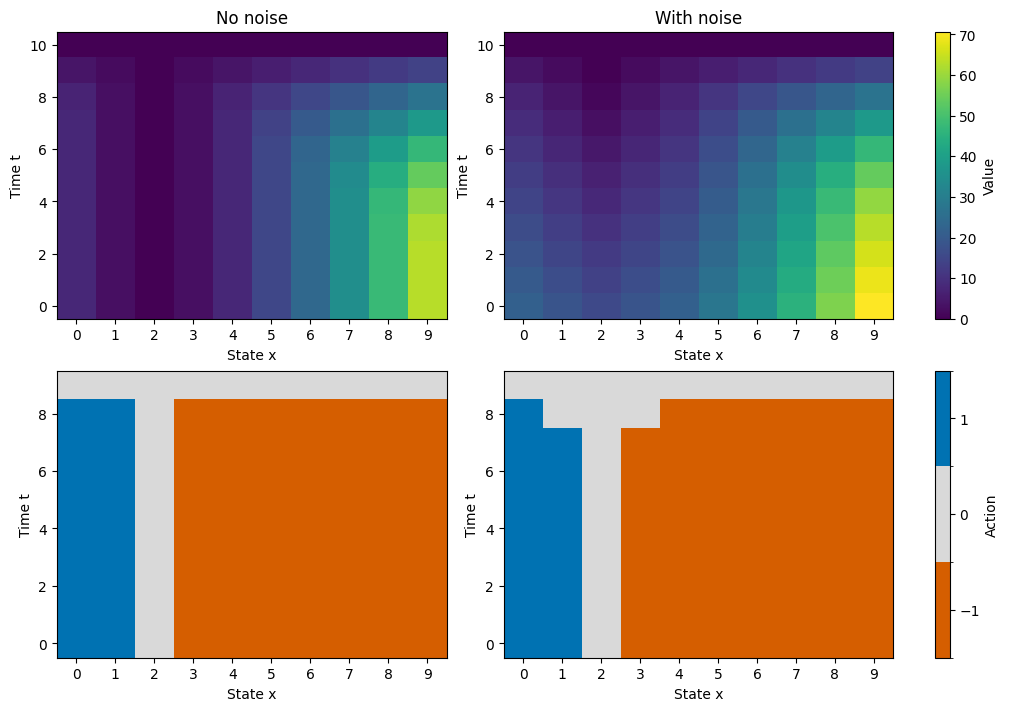

In [15]:
# Same grid world, with noise at every transition.
env_grid_noise = GridWorld(
    x_min=0,
    x_max=9,
    target=2,
    T=10,
    p_noise=np.tile([0.3, 0.4, 0.3],(10,1)),
)

V_noise, alpha_noise = compute_value_function(env_grid_noise)

plot_grid_comparison(
    env_grid,
    [
        ("No noise", V_grid, alpha_grid),
        ("With noise", V_noise, alpha_noise),
    ],
)

## Five-state grid world

We now use the five-state space from the slides:

$$
\mathcal X=\{1,2,3,4,5\},\qquad
\mathcal A=\{-1,0,1\},\qquad x^\ast=3.
$$

The running cost is

$$
c(x,a)=2\mathbf 1_{\{x\ne 3\}}+|a|,
$$

and the terminal cost is zero. We compare no noise with independent uniform noise at every transition. Here $T=5$.

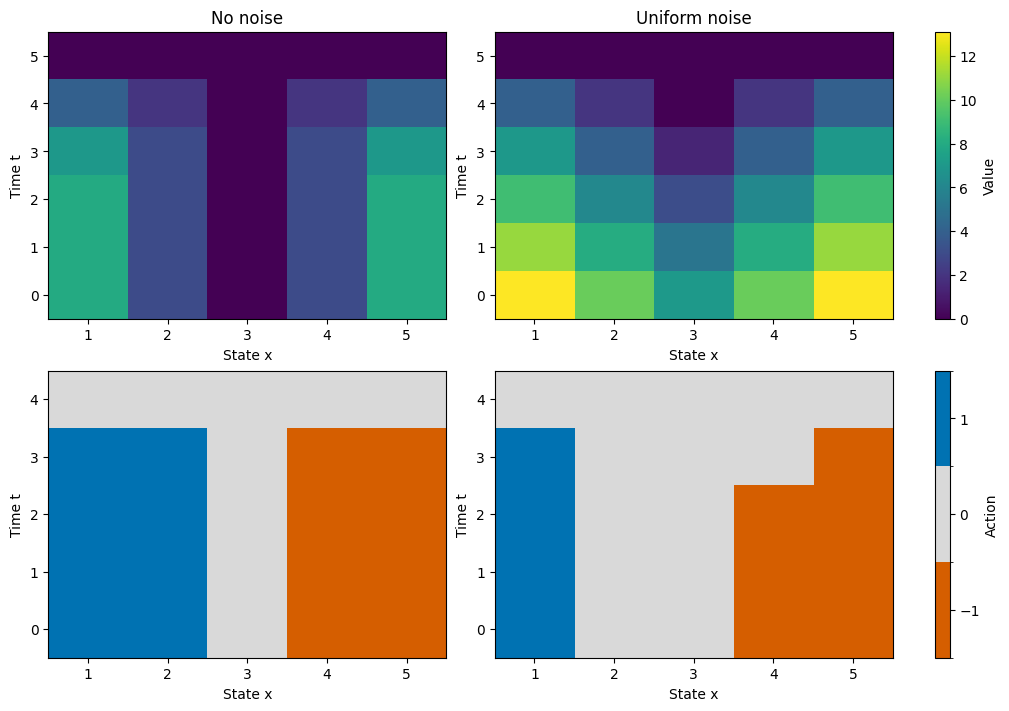

No noise:      V_0(3) = 0.000
Uniform noise: V_0(3) = 7.111


In [18]:
env_five_det = GridWorld(
    x_min=1,
    x_max=5,
    target=3,
    T=5,
    p_noise=np.tile([0.0, 1.0, 0.0],(5,1)),
)

env_five_noise = GridWorld(
    x_min=1,
    x_max=5,
    target=3,
    T=5,
    p_noise=np.tile([1/3, 1/3, 1/3],(5,1)),
)

V_five_det, alpha_five_det = compute_value_function(env_five_det)
V_five_noise, alpha_five_noise = compute_value_function(env_five_noise)

plot_grid_comparison(
    env_five_det,
    [
        ("No noise", V_five_det, alpha_five_det),
        ("Uniform noise", V_five_noise, alpha_five_noise),
    ],
)

# State 3 is at array index 2.
print(f"No noise:      V_0(3) = {V_five_det[0, 2]:.3f}")
print(f"Uniform noise: V_0(3) = {V_five_noise[0, 2]:.3f}")

## Two-step example from the slides

Now let $T=2$, with zero running cost and terminal cost

$$
g(x)=|x-3|.
$$

There is uniform noise in the first transition and no noise in the second. We start at $x_0=3$.

We compare a feedback policy with a time-only control: the latter must choose both actions before observing the noise.

In [19]:
env_two_step = GridWorld(
    x_min=1,
    x_max=5,
    target=3,
    T=2,
    p_noise=[
        [1/3, 1/3, 1/3],  # First transition: uniform noise
        [0.0, 1.0, 0.0],  # Second transition: no noise
    ],
    state_cost=0.0,
    action_cost=0.0,
    terminal_weight=1.0,
)

V_two, alpha_two = compute_value_function(env_two_step)

# State 3 is at array index 2.
print(f"Optimal feedback value V_0(3): {V_two[0, 2]:.3f}")

# At time 1, inspect the feedback action at states 2, 3, and 4.
for x in [2, 3, 4]:
    print(f"Feedback action at time 1, state {x}: {alpha_two[1, x - 1]}")

# Enumerate time-only controls (a_0, a_1).
time_only_costs = []

for a0 in env_two_step.actions:
    for a1 in env_two_step.actions:
        expected_cost = 0.0

        for p, e in zip(env_two_step.p_noise[0], env_two_step.noise):
            x1 = env_two_step.transition(3, a0, e)
            x2 = env_two_step.transition(x1, a1, 0)
            expected_cost += p * env_two_step.terminal_cost(x2)

        time_only_costs.append(expected_cost)

print(f"Best time-only value: {min(time_only_costs):.3f}")

Optimal feedback value V_0(3): 0.000
Feedback action at time 1, state 2: 1
Feedback action at time 1, state 3: 0
Feedback action at time 1, state 4: -1
Best time-only value: 0.667


## Exercises
- explain intuitively the form of the optimal control
- try various noise distributions
- optimize the computations by using vector-matrix operations instead of loops as much as possible


# Example 2: Knowledge vs Stress

## Definition of the problem

In [20]:
# Parameters
K = 11  # Number of knowledge levels: {0, ..., 10}
S = 5   # Number of stress levels: {1, ..., 5}
A = 2   # Number of actions: {0, 1}
T = 12  # Number of decisions

# Costs
c_stress = 1      # Stress cost
c_effort = 1      # Effort cost
c_knowledge = 1  # Terminal reward per unit of knowledge

# Knowledge and stress shocks are independent.
p_noise_k = np.array([0.1, 0.9])  # Probabilities for epsilon_k: {-1, 0}
p_noise_s = np.array([0.9, 0.1])  # Probabilities for epsilon_s: {0, 1}

# State and action spaces
states_k = np.arange(K)  # Knowledge levels {0, ..., K - 1}
states_s = np.arange(1, S + 1)  # Stress levels {1, ..., 5}
actions = np.array([0, 1])  # Actions {0, 1}

# Cost function
def cost(state, a):
    """
    state  = (k, s)
    """
    k, s = state

    # Running cost: current stress plus the cost of effort.
    return c_stress * s + c_effort * a

# Transition function
def transition(state, a, noises):
    """
    state  = (k, s)
    shocks = (e_k, e_s)
    """
    k, s = state
    e_k, e_s = noises

    # Action 1 increases knowledge and reduces stress before noise.
    next_k = k + a + e_k
    next_s = s - a + e_s

    # Clip the next state to the allowed knowledge and stress levels.
    if K is not None:
        next_k = max(0, min(K - 1, next_k))
    if S is not None:
        next_s = max(1, min(S, next_s))

    return next_k, next_s

## Dynamic programming for V and control

ChatGPT version: WRONG!

In [21]:
# Initialize value function and optimal control policy
V = np.zeros((T + 1, K, S))  # Values at times 0, ..., T; Shape: (time steps, knowledge levels, stress levels)
alpha = np.zeros((T, K, S), dtype=int)  # Actions at times 0, ..., T - 1

# Dynamic programming
for t in reversed(range(T)):  # Backward pass: T - 1, ..., 0
    for k in states_k:
        for s in states_s:
            expected_values = []
            for a in actions:
                value = 0
                # Transition dynamics for k and s
                for i, e_k in enumerate([-1, 0]):  # Noise for k
                    for j, e_s in enumerate([0, 1]):  # Noise for s
                        next_k, next_s = transition((k, s), a, (e_k, e_s))
                        value += p_noise_k[i] * p_noise_s[j] * V[t + 1, next_k, next_s - 1]
                # Running cost
                running_cost = cost((k, s), a)
                expected_values.append(running_cost + value)

            # Find the optimal action
            # For an exact tie, argmin returns the first minimizing action.
            # Floating-point rounding can make theoretical ties look unequal.
            best_action_index = np.argmin(expected_values)
            best_action = actions[best_action_index]

            # Update value function and control policy
            V[t, k, s - 1] = expected_values[best_action_index]
            alpha[t, k, s - 1] = best_action

# Terminal cost: reward knowledge through g(k, s) = -c_knowledge * k.
for k in states_k:
    for s in states_s:
        V[-1, k, s - 1] = -c_knowledge * k

# Results
print("Optimal Value Function V:\n", V)
print("Optimal Control Policy alpha:\n", alpha)


Optimal Value Function V:
 [[[ 14.1         16.1         19.21111111  23.43333332  28.76666623]
  [ 14.1         16.1         19.21111111  23.43333332  28.76666623]
  [ 14.1         16.1         19.21111111  23.43333332  28.76666623]
  [ 14.1         16.1         19.21111111  23.43333332  28.76666623]
  [ 14.1         16.1         19.21111111  23.43333332  28.76666623]
  [ 14.1         16.1         19.21111111  23.43333332  28.76666623]
  [ 14.1         16.1         19.21111111  23.43333332  28.76666623]
  [ 14.1         16.1         19.21111111  23.43333332  28.76666623]
  [ 14.1         16.1         19.21111111  23.43333332  28.76666623]
  [ 14.1         16.1         19.21111111  23.43333332  28.76666623]
  [ 14.1         16.1         19.21111111  23.43333332  28.76666623]]

 [[ 12.9         14.9         18.01111111  22.23333324  27.56666315]
  [ 12.9         14.9         18.01111111  22.23333324  27.56666315]
  [ 12.9         14.9         18.01111111  22.23333324  27.56666315]
  [ 1

Corrected version: the terminal value should be computed first (so that the backward pass is correctly initialized).

In [22]:
# Initialize value function and optimal control policy
V = np.zeros((T + 1, K, S))  # Values at times 0, ..., T
alpha = np.zeros((T, K, S), dtype=int)  # Actions at times 0, ..., T - 1

# Terminal cost: reward knowledge through g(k, s) = -c_knowledge * k.
for k in states_k:
    for s in states_s:
        V[-1, k, s - 1] = -c_knowledge * k

# Dynamic programming
for t in reversed(range(T)):  # Backward pass: T - 1, ..., 0
    for k in states_k:
        for s in states_s:
            expected_values = []
            for a in actions:
                value = 0
                # Transition dynamics for k and s
                for i, e_k in enumerate([-1, 0]):  # Noise for k
                    for j, e_s in enumerate([0, 1]):  # Noise for s
                        next_k, next_s = transition((k, s), a, (e_k, e_s))
                        value += p_noise_k[i] * p_noise_s[j] * V[t + 1, next_k, next_s - 1]
                # Running cost
                running_cost = cost((k, s), a)
                expected_values.append(running_cost + value)

            # Find the optimal action
            # For an exact tie, argmin returns the first minimizing action.
            # Floating-point rounding can make theoretical ties look unequal.
            best_action_index = np.argmin(expected_values)
            best_action = actions[best_action_index]

            # Update value function and control policy
            V[t, k, s - 1] = expected_values[best_action_index]
            alpha[t, k, s - 1] = best_action

# Results
print("Optimal Value Function V:\n", V)
print("Optimal Control Policy alpha:\n", alpha)


Optimal Value Function V:
 [[[ 13.21110644  14.34597849  16.56820071  19.90153416  24.34598095]
  [ 12.31540501  13.42651612  15.64873839  18.98207347  23.42655249]
  [ 11.41936744  12.53047857  14.75270191  18.08606395  22.53093292]
  [ 10.52955301  11.64066467  13.86290969  17.19664573  21.64514167]
  [  9.64062303  10.75175051  12.97436334  16.31178639  20.7828217 ]
  [  8.75175051   9.86325244  12.08957973  15.44981375  20.01311542]
  [  7.86325244   8.97847242  11.22773449  14.68185289  19.48852418]
  [  6.97847242   8.11666288  10.46075456  14.16640434  19.33074075]
  [  6.11666288   7.35005545   9.95215384  14.04139797  19.30814409]
  [  5.35005545   6.84535902   9.86340358  14.02907305  19.30659732]
  [  4.84535902   6.79768506   9.85888725  14.02864379  19.30655637]]

 [[ 12.09999533  13.21110644  15.43332875  18.76666282  23.2111084 ]
  [ 11.13874205  12.24985316  14.47207541  17.80540959  22.24987158]
  [ 10.22392311  11.33503423  13.55725696  16.89060504  21.3352981 ]
  [  

## Plotting the solution

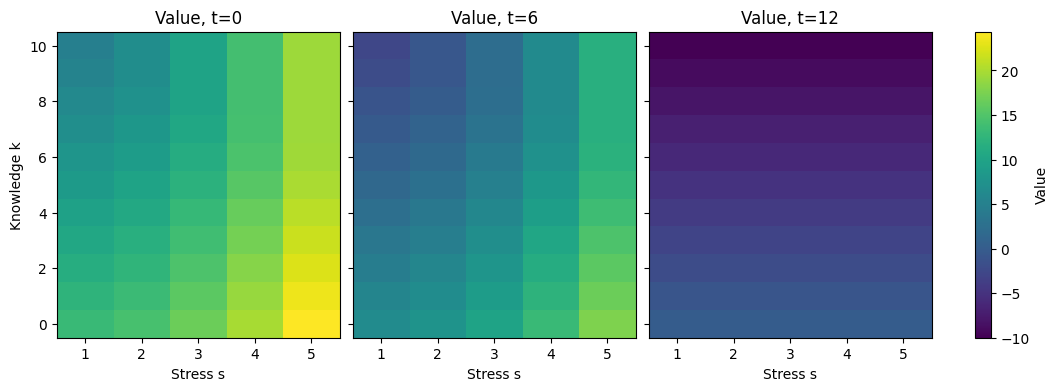

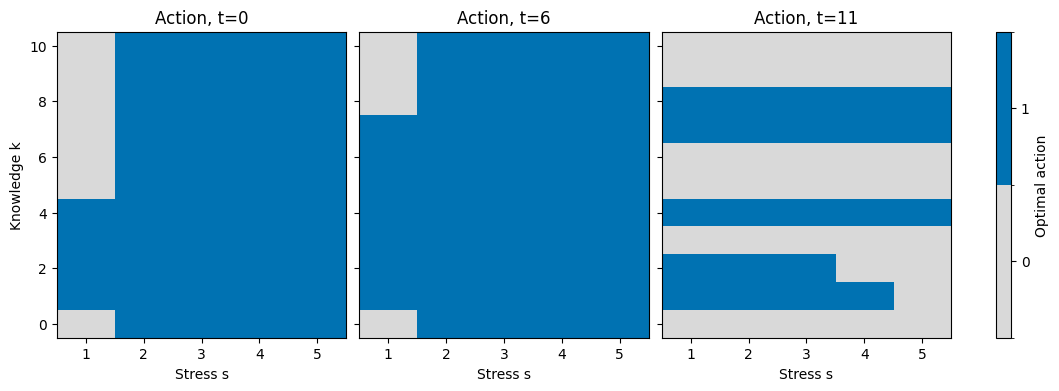

In [23]:
def plot_knowledge_snapshots(
    V, alpha, value_times=None, policy_times=None
):
    """
    Plot selected value and policy snapshots.

    V has T + 1 time slices; alpha has T time slices.
    """

    T = alpha.shape[0]
    K, S = alpha.shape[1:]

    if value_times is None:
        value_times = sorted(set([0, T // 2, T]))

    if policy_times is None:
        policy_times = sorted(set([0, T // 2, T - 1]))

    extent = [0.5, S + 0.5, -0.5, K - 0.5]

    # Value snapshots: one shared color scale.
    fig, axes = plt.subplots(
        1, len(value_times),
        figsize=(3.5 * len(value_times), 3.8),
        sharex=True,
        sharey=True,
        squeeze=False,
        constrained_layout=True,
    )

    for ax, t in zip(axes[0], value_times):
        value_plot = ax.imshow(
            V[t],
            origin="lower",
            aspect="auto",
            cmap="viridis",
            vmin=V.min(),
            vmax=V.max(),
            extent=extent,
            interpolation="nearest",
        )
        ax.set_title(f"Value, t={t}")
        ax.set_xlabel("Stress s")

    axes[0, 0].set_ylabel("Knowledge k")
    fig.colorbar(value_plot, ax=axes.ravel().tolist(), label="Value")
    plt.show()

    # Policy snapshots: fixed colors for actions 0 and 1.
    action_cmap = ListedColormap(["#D9D9D9", "#0072B2"])
    action_norm = BoundaryNorm([-0.5, 0.5, 1.5], action_cmap.N)

    fig, axes = plt.subplots(
        1, len(policy_times),
        figsize=(3.5 * len(policy_times), 3.8),
        sharex=True,
        sharey=True,
        squeeze=False,
        constrained_layout=True,
    )

    for ax, t in zip(axes[0], policy_times):
        action_plot = ax.imshow(
            alpha[t],
            origin="lower",
            aspect="auto",
            cmap=action_cmap,
            norm=action_norm,
            extent=extent,
            interpolation="nearest",
        )
        ax.set_title(f"Action, t={t}")
        ax.set_xlabel("Stress s")

    axes[0, 0].set_ylabel("Knowledge k")
    fig.colorbar(
        action_plot, ax=axes.ravel().tolist(),
        ticks=[0, 1], label="Optimal action",
    )
    plt.show()


plot_knowledge_snapshots(V, alpha)

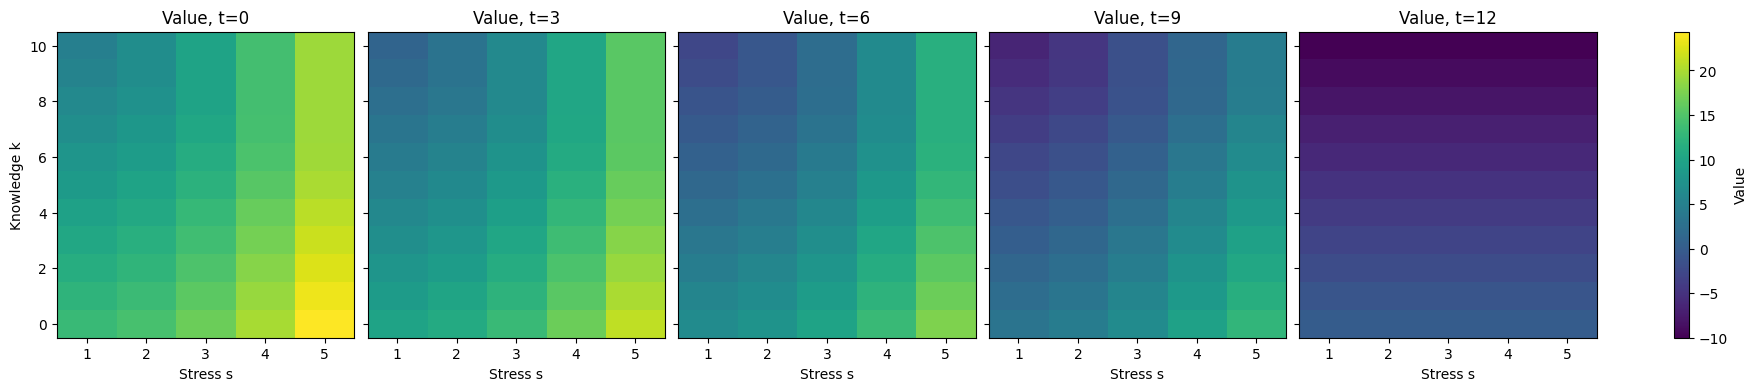

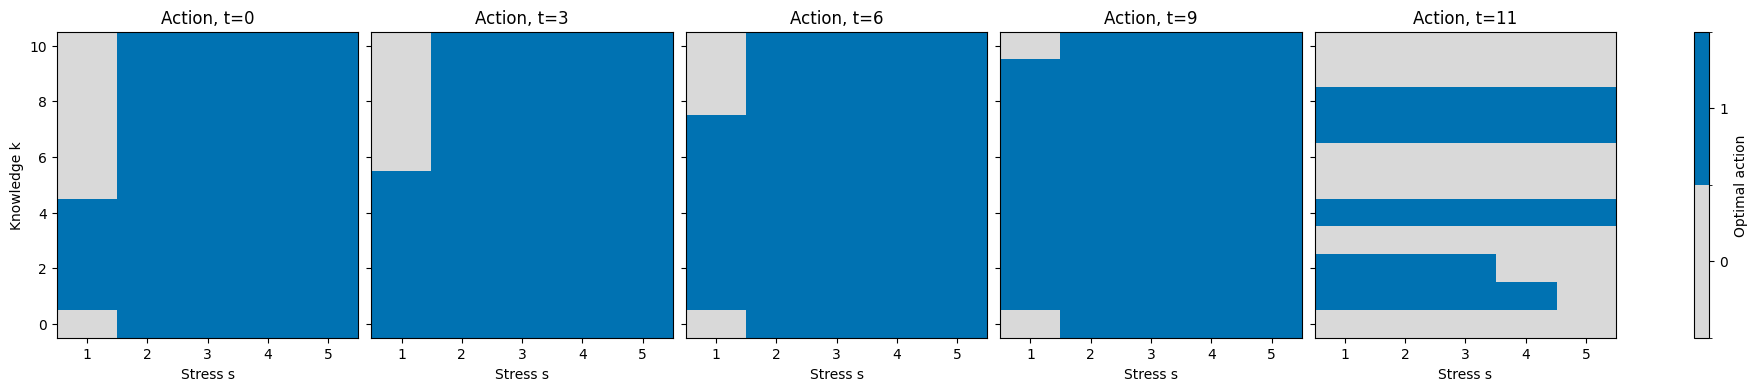

In [24]:
# Inspecting other time steps
plot_knowledge_snapshots(
    V, alpha,
    value_times=[0, 3, 6, 9, 12],
    policy_times=[0, 3, 6, 9, 11],
)

## Exercises
- explain the strange shape of the control
- try other values of noise probabilities, e.g., [0.5, 0.5]
- try larger value of knowledge, e.g., c_knowledge = 10